# Portfolio copy
Adapted from completed course notebooks. We retain the original model and analysis code; Google Drive mounting and the course-specific download link were replaced with local dataset instructions. Saved outputs come from the original notebook runs and have not been regenerated.


# Biomedical Imaging and Pytorch IV:
# Data Augmentation and Early Stopping

## `NoteBook Practice 9`

---
Modify the notebook as necessary to improve the performance parameters of a model you create. Try to use a metric that combines the partial metrics to show that your model classifies better than the baseline model shown in this notebook.


### 1. **Setting up Our Workspace**


En primer lugar, verifico y muestro la GPU disponible.

In [ ]:
!nvidia-smi

Sun Nov 30 16:36:16 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P0             26W /   70W |    3328MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Defino el directorio principal (HOME).

In [ ]:
# Configuro nuestra $HOME to /content

import os
HOME = os.getcwd()
print(HOME)

/content


Integro Google Drive en mi notebook, autorizando su acceso.

Google Drive mounting was removed from this portfolio copy. Place the dataset archive locally as described in the README.

## 2. Load a Dataset (Dataloader)


Creo un directorio donde guardo mi dataset.

In [ ]:
# Creo el directorio del dataset
import os
datasets_dir = os.path.join(HOME, "datasets")
os.makedirs(datasets_dir, exist_ok=True)
print(os.getcwd())

/content


Descargo el dataset y obtengo nuevos conjuntos de datos.

In [ ]:
import os, zipfile
from pathlib import Path
os.chdir(datasets_dir)
archive = Path("exp4val.zip")
if not archive.is_file():
    raise FileNotFoundError("Place the course dataset archive exp4val.zip in the datasets directory. See README.")
with zipfile.ZipFile(archive) as dataset_zip:
    root = Path.cwd().resolve()
    for member in dataset_zip.infolist():
        if not (root / member.filename).resolve().is_relative_to(root):
            raise ValueError("Unsafe dataset archive path")
    dataset_zip.extractall(root)


### Inspect the Dataset: Skin Lesion Detection in 7 Classes


Visualizo la estructura de os datos mediante un árbol de directorios: organiza los datos antes de cargarlos.

In [ ]:
!apt-get install -q tree

!tree -L 2 -d $datasets_dir

Reading package lists...
Building dependency tree...
Reading state information...
tree is already the newest version (2.0.2-1).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.
/content/datasets
├── test
│   ├── class_0
│   ├── class_1
│   ├── class_2
│   ├── class_3
│   ├── class_4
│   ├── class_5
│   └── class_6
├── train
│   ├── class_0
│   ├── class_1
│   ├── class_2
│   ├── class_3
│   ├── class_4
│   ├── class_5
│   └── class_6
└── val
    ├── class_0
    ├── class_1
    ├── class_2
    ├── class_3
    ├── class_4
    ├── class_5
    └── class_6

24 directories


Visualizo 6 imagenes de ejemplo del dataset para comprobar que el formato sea razonable, saber su tamaño (256, 256, 3) con formato jpg.

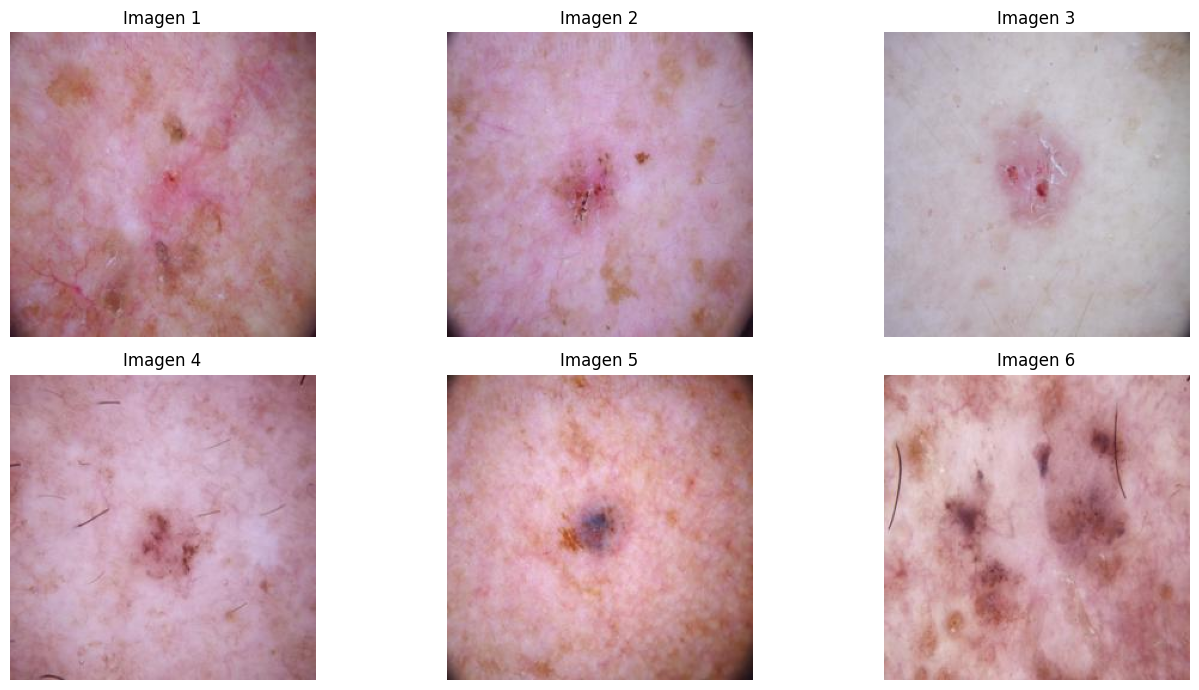


 Size of image:  (256, 256, 3)


In [ ]:
# Creo un dibujo con subplots organizados en una cuadrícula de 2x4
import matplotlib.pyplot as plt
import glob
import matplotlib.image as mpimg

# Directorio de las imagenes
image_directory = f'{HOME}/datasets/test/class_1/'

# Lista de rutas de imágenes
image_paths = glob.glob(image_directory + '*.jpg')[:6]

# Configurar el dibujo con los subplots
fig, axs = plt.subplots(2, 3, figsize=(14, 7))

# Iterar a través de las imágenes y mostrarlas en los subplots.
for i, image_path in enumerate(image_paths):
    row = i // 3
    col = i % 3
    img = mpimg.imread(image_path)
    axs[row, col].imshow(img)
    axs[row, col].set_title(f'Imagen {i + 1}')
    axs[row, col].axis('off')

plt.tight_layout()
plt.show()
print("\n Size of image: ", img.shape)

### Setting a Dataloader


Importo la librerías necesarias

In [ ]:
import torch
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, ConcatDataset

Calcular la media y la desviación estándar en el conjunto de entrenamiento. Directorio de datos de entrenamiento, validación y prueba (conversión a tensores).

In [ ]:
%%time

train_dir = f"{HOME}/datasets/train/"
val_dir  = f"{HOME}/datasets/val/"
test_dir   = f"{HOME}/datasets/test/"

# transform: para calcular la media y la desviación estándar
transform = transforms.Compose([
    transforms.ToTensor()  # transforma imágenes en tensor
])

# Carga el conjunto de datos ImageFolder y aplica la transformación
dataset = datasets.ImageFolder(root= train_dir, transform=transform)

loader = DataLoader(dataset, batch_size=1, shuffle=False)

# Inicializa variables para almacenar la suma de los valores de los píxeles y la desviación estándar.
mean_sum = 0.0
std_sum = 0.0
total_samples = 0

# Itera sobre el dataloader (loader),
# calcula la media y la desviación estándar en todos los canales para cada lote (0) y dimensiones espaciales (alto (2) y ancho (3))
for images, _ in loader:
    mean_sum += torch.mean(images, dim=[0, 2, 3])
    std_sum += torch.std(images, dim=[0, 2, 3])
    total_samples += 1

mean = mean_sum / total_samples
std = std_sum / total_samples

print("Total train samples:", total_samples)
print("Mean:", mean)
print("Std:", std)

Total train samples: 7350
Mean: tensor([0.7536, 0.5706, 0.6018])
Std: tensor([0.0849, 0.1106, 0.1187])
CPU times: user 20.4 s, sys: 210 ms, total: 20.6 s
Wall time: 20.7 s


↑ Estos datos de salida de arriba los cogeremos luego para normalizar.

Defino las transformaciones de augmentación que se aplicarán a cada conjunto de datos transformado.

In [ ]:
%%time

transformations = [
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(96, padding=6, padding_mode='reflect'),
    transforms.RandomRotation(20, fill=(0, 0, 0)), #Aumento RandomRotation
    #Al rotar rellenamos la imagen para mantener su forma
    transforms.ColorJitter(brightness=0.6, contrast=0.6, saturation=0.6),

    #Añadimos una deformación geométrica suave del ±3°
    transforms.RandomAffine(degrees=3, translate=(0.1, 0.1), scale=(0.8, 0.8), fill=(0, 0, 0)),

    transforms.GaussianBlur(kernel_size=5), #ruido
    transforms.RandomResizedCrop(96),
]

# Se agrega la transformación ToTensor() y Normalize() a cada transformación de datos.
for i in range(len(transformations)):
    transformations[i] = transforms.Compose([#
        transformations[i],
        transforms.Resize((96,96)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])

print(transformations)

[Compose(
    RandomHorizontalFlip(p=0.5)
    Resize(size=(96, 96), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=tensor([0.7536, 0.5706, 0.6018]), std=tensor([0.0849, 0.1106, 0.1187]))
), Compose(
    RandomCrop(size=(96, 96), padding=6)
    Resize(size=(96, 96), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=tensor([0.7536, 0.5706, 0.6018]), std=tensor([0.0849, 0.1106, 0.1187]))
), Compose(
    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=(0, 0, 0))
    Resize(size=(96, 96), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=tensor([0.7536, 0.5706, 0.6018]), std=tensor([0.0849, 0.1106, 0.1187]))
), Compose(
    ColorJitter(brightness=(0.4, 1.6), contrast=(0.4, 1.6), saturation=(0.4, 1.6), hue=None)
    Resize(size=(96, 96), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=tensor([0.7536, 0

Normalizo y creo ImageFolder para los conjuntos de datos de entrenamiento, validación y test con tamaño 96*96

In [ ]:
%%time

# Normalizo el conjunto de entrenamiento
train_data = datasets.ImageFolder(train_dir,transform = transforms.Compose([
    transforms.Resize((96,96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])
)

# Normalizo los conjuntos de validacion y test usando las mismas estadísticas calculadas en el de entrenamiento.
val_set = datasets.ImageFolder(val_dir,transform = transforms.Compose([
    transforms.Resize((96,96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])
)

test_set = datasets.ImageFolder(test_dir,transform = transforms.Compose([
    transforms.Resize((96,96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])
)

print(f"Length of Train Data :{len(train_data)}")
print(f"Length of Validation Data : {len(val_set)}")
print(f"Length of Test Data : {len(test_set)}")

classes = train_data.classes
print('Classes: ', classes)

Length of Train Data :7350
Length of Validation Data : 1050
Length of Test Data : 210
Classes:  ['class_0', 'class_1', 'class_2', 'class_3', 'class_4', 'class_5', 'class_6']
CPU times: user 17.4 ms, sys: 1.05 ms, total: 18.5 ms
Wall time: 19.2 ms


Aplico cada transformación por separado a un dataset transformado y las concateno.

In [ ]:

train_set = train_data
for transform in transformations:
    transformed_data = datasets.ImageFolder(train_dir,transform = transform)
    train_set = ConcatDataset([train_set, transformed_data])

print(f"Length of Train Data :{len(train_set)}")
print(f"Length of Validation Data : {len(val_set)}")
print(f"Length of Test Data : {len(test_set)}")


Length of Train Data :58800
Length of Validation Data : 1050
Length of Test Data : 210


### Display an image and its transformations

Muestro una imagen aleatoria del dataset junto con su clase usando un DalataLoader simple (ajustado a batch_size=32 y num_workers=4)

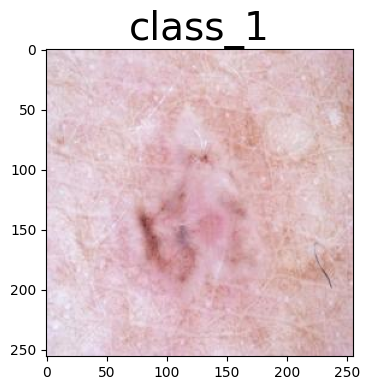

In [ ]:
import itertools
import numpy as np
import os
import matplotlib.pyplot as plt
from torchvision import transforms

# Defino una transformación mínima que sólo convierte a tensor
basic_transform = transforms.Compose([
    transforms.ToTensor()
])

# DataLoader que no aplica las transformaciones complejas, sólo convierte a tensor
basic_dataloader = torch.utils.data.DataLoader(
    datasets.ImageFolder(train_dir, transform=basic_transform),
    batch_size=32,
    shuffle=True
)

# Obtengo filas y columnas para la figura
nrows, ncols = 1, 1  # Solo una imagen

# Configuro la figura
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*4), subplot_kw={'facecolor': "#ebf5ff"})

# Obtenengo un índice aleatorio
rb_index = np.random.randint(0, len(basic_dataloader))

# Obtengo el batch correspondiente al índice aleatorio
imgs, labels = next(itertools.islice(basic_dataloader, rb_index, rb_index + 1))

# Muestro la imagen y su etiqueta
ax.set_title(classes[labels[0]], fontsize=28)
ax.imshow(imgs[0].permute(1, 2, 0))
fig.tight_layout()
plt.show()


Visualizo una imagen con cada una de las transformaciones aplicadas

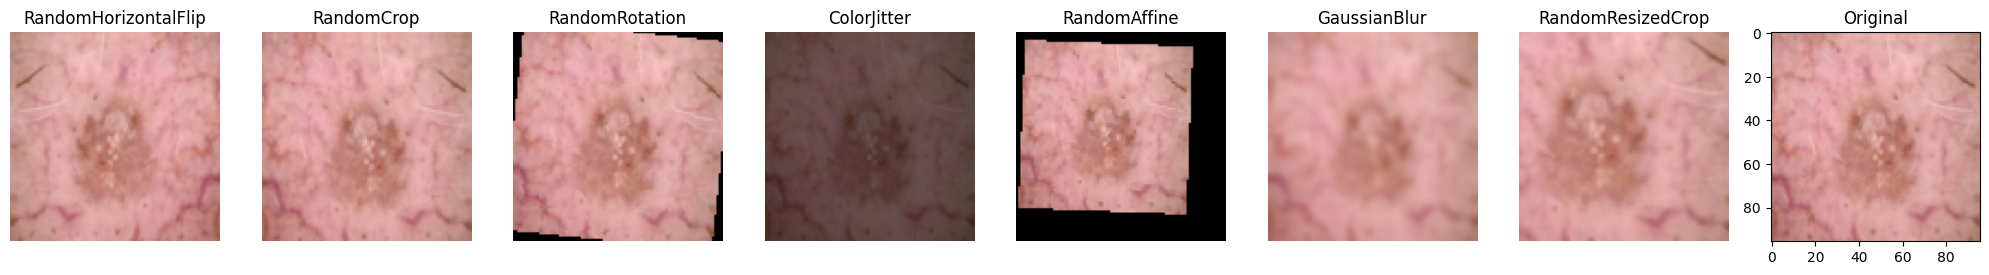

In [ ]:
from torchvision.transforms import ToPILImage
import random

# Convierto la imagen tensorial a PIL para visualizar las transformaciones.
to_pil = ToPILImage()

# Creo una transformación de desnormalización
inv_normalize = transforms.Normalize(
    mean=[-m/s for m, s in zip(mean, std)],
    std=[1/s for s in std]
)

img = next(img for img,label in train_set)

# Configuro la figura con subplots (longitud de las transformaciones + original)
fig, axs = plt.subplots(1, len(transformations)+1, figsize=(20, 5))

for i, transform in enumerate(transformations):
    transformed_image = transform(to_pil(inv_normalize(img)))

    axs[i].imshow(inv_normalize(transformed_image).permute(1, 2, 0))
    axs[i].set_title(type(transform.transforms[0]).__name__)
    axs[i].axis('off')
axs[i+1].set_title('Original')
axs[i+1].imshow(inv_normalize(img).permute(1, 2, 0))

plt.tight_layout()
plt.show()

### Displaying all classes


Muestro una imagen por cada clase desenormalizada

CPU times: user 29.8 s, sys: 626 ms, total: 30.5 s
Wall time: 30.6 s


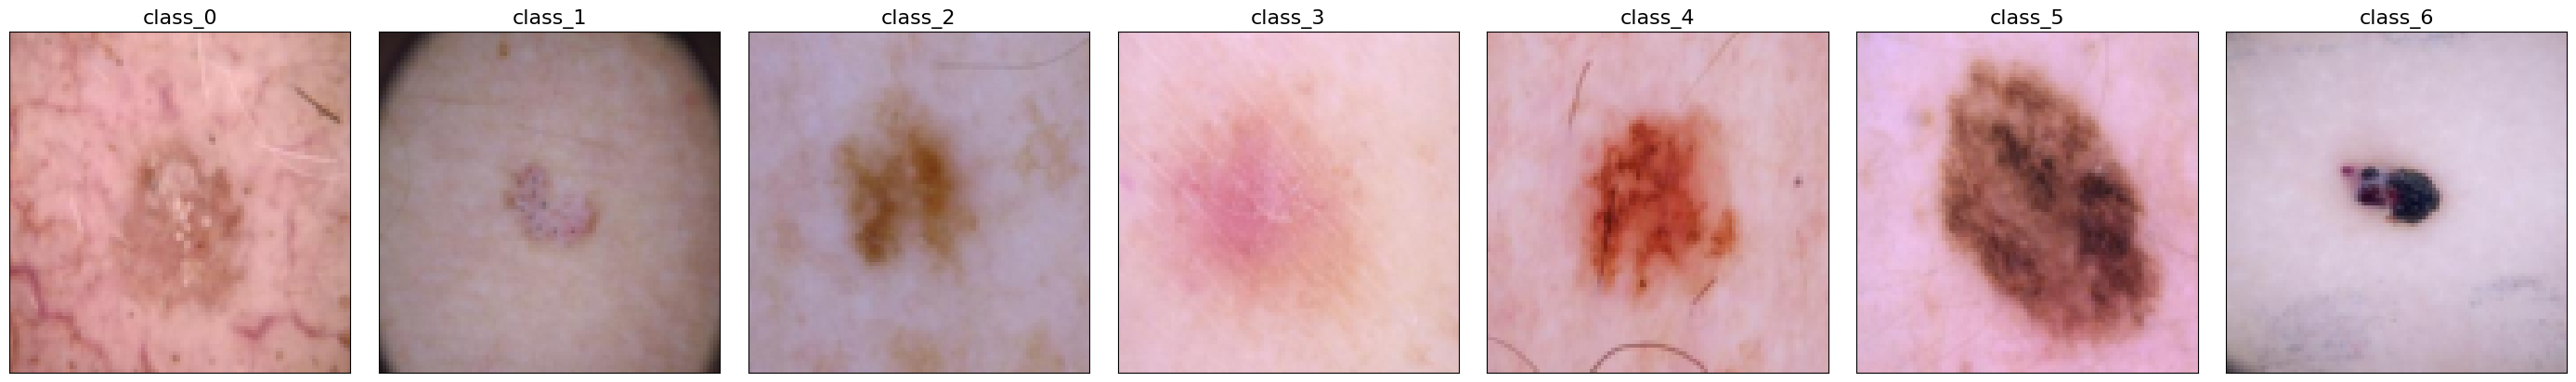

In [ ]:
%%time
inv_normalize = transforms.Normalize(
  mean= [-m/s for m, s in zip(mean, std)],
  std= [1/s for s in std]
)

fig, ax = plt.subplots(nrows=1, ncols=len(classes), figsize=(7*4,1*4),
                       subplot_kw={'facecolor': "#ebf5ff"})

for i, ax in enumerate(ax.flatten()):
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_title(classes[i], fontsize=16)
  img = next(img for img,label in train_set if label == i)
  ax.imshow(inv_normalize(img).permute(1,2,0)) # para las no normalizadas

fig.tight_layout()


### Settings Hyperparameters


Aumento el batch size a 64 (aprendizaje estable), defino 20 épocas de entrenamiento y 7 clases.

In [ ]:
# batch size define cuántas muestras de entrenamiento o de test se utiliza en una sola iteración
batch_size = 32
# epochs define el número de iteraciones
epochs = 40
# num_classes define el número de la clase
num_classes = len(classes)

print(f"Number of Classes: {num_classes}")
print(f'Number of epochs: {epochs}')
print(f'Batch size: {batch_size}')

Number of Classes: 7
Number of epochs: 40
Batch size: 32


Creamos dataloaders para el bucle de entrenamiento y validación.

In [ ]:
%%time

train_dataloader = DataLoader(
  train_set,
  batch_size=batch_size,
  shuffle=True,
  num_workers=4) #Prefetching: mientras entrena con un batch, va preparando el siguiente.
  #Con un num_workers más alto mejoramos la velocidad de carga

val_dataloader = DataLoader(
  val_set,
  batch_size=batch_size,
  shuffle=False, #En la validación el orden no importa porque no se entrena.
  num_workers=4)

CPU times: user 5.49 ms, sys: 2.01 ms, total: 7.5 ms
Wall time: 7.66 ms


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Defino la función que determina las columnas y filas necesarias para un número de imágenes dado

In [ ]:

def rows_cols(input):

    divisors = []

    for i in range(1, input+1):
        if input % i == 0:
            divisors.append(i)

    # Tamaño de la lista de divisores.
    n = len(divisors)

    # Si el tamaño es impar, el elemento en el medio es la mediana.
    if n % 2 != 0:
        median_index = (n - 1) // 2
        rows = divisors[median_index]
    # Si el tamaño es par, los dos elementos del medio son iguales.
    else:
        median_index1 = n // 2 - 1
        rows = divisors[median_index1]

    cols = int(input/rows)
    return rows, cols


Voy visualizando las imágenes, mostrando tanto las originales como las transformadas (muestro batch aleatorio).

<class 'torch.Tensor'> torch.Size([32, 3, 96, 96])
CPU times: user 894 ms, sys: 334 ms, total: 1.23 s
Wall time: 30.6 s


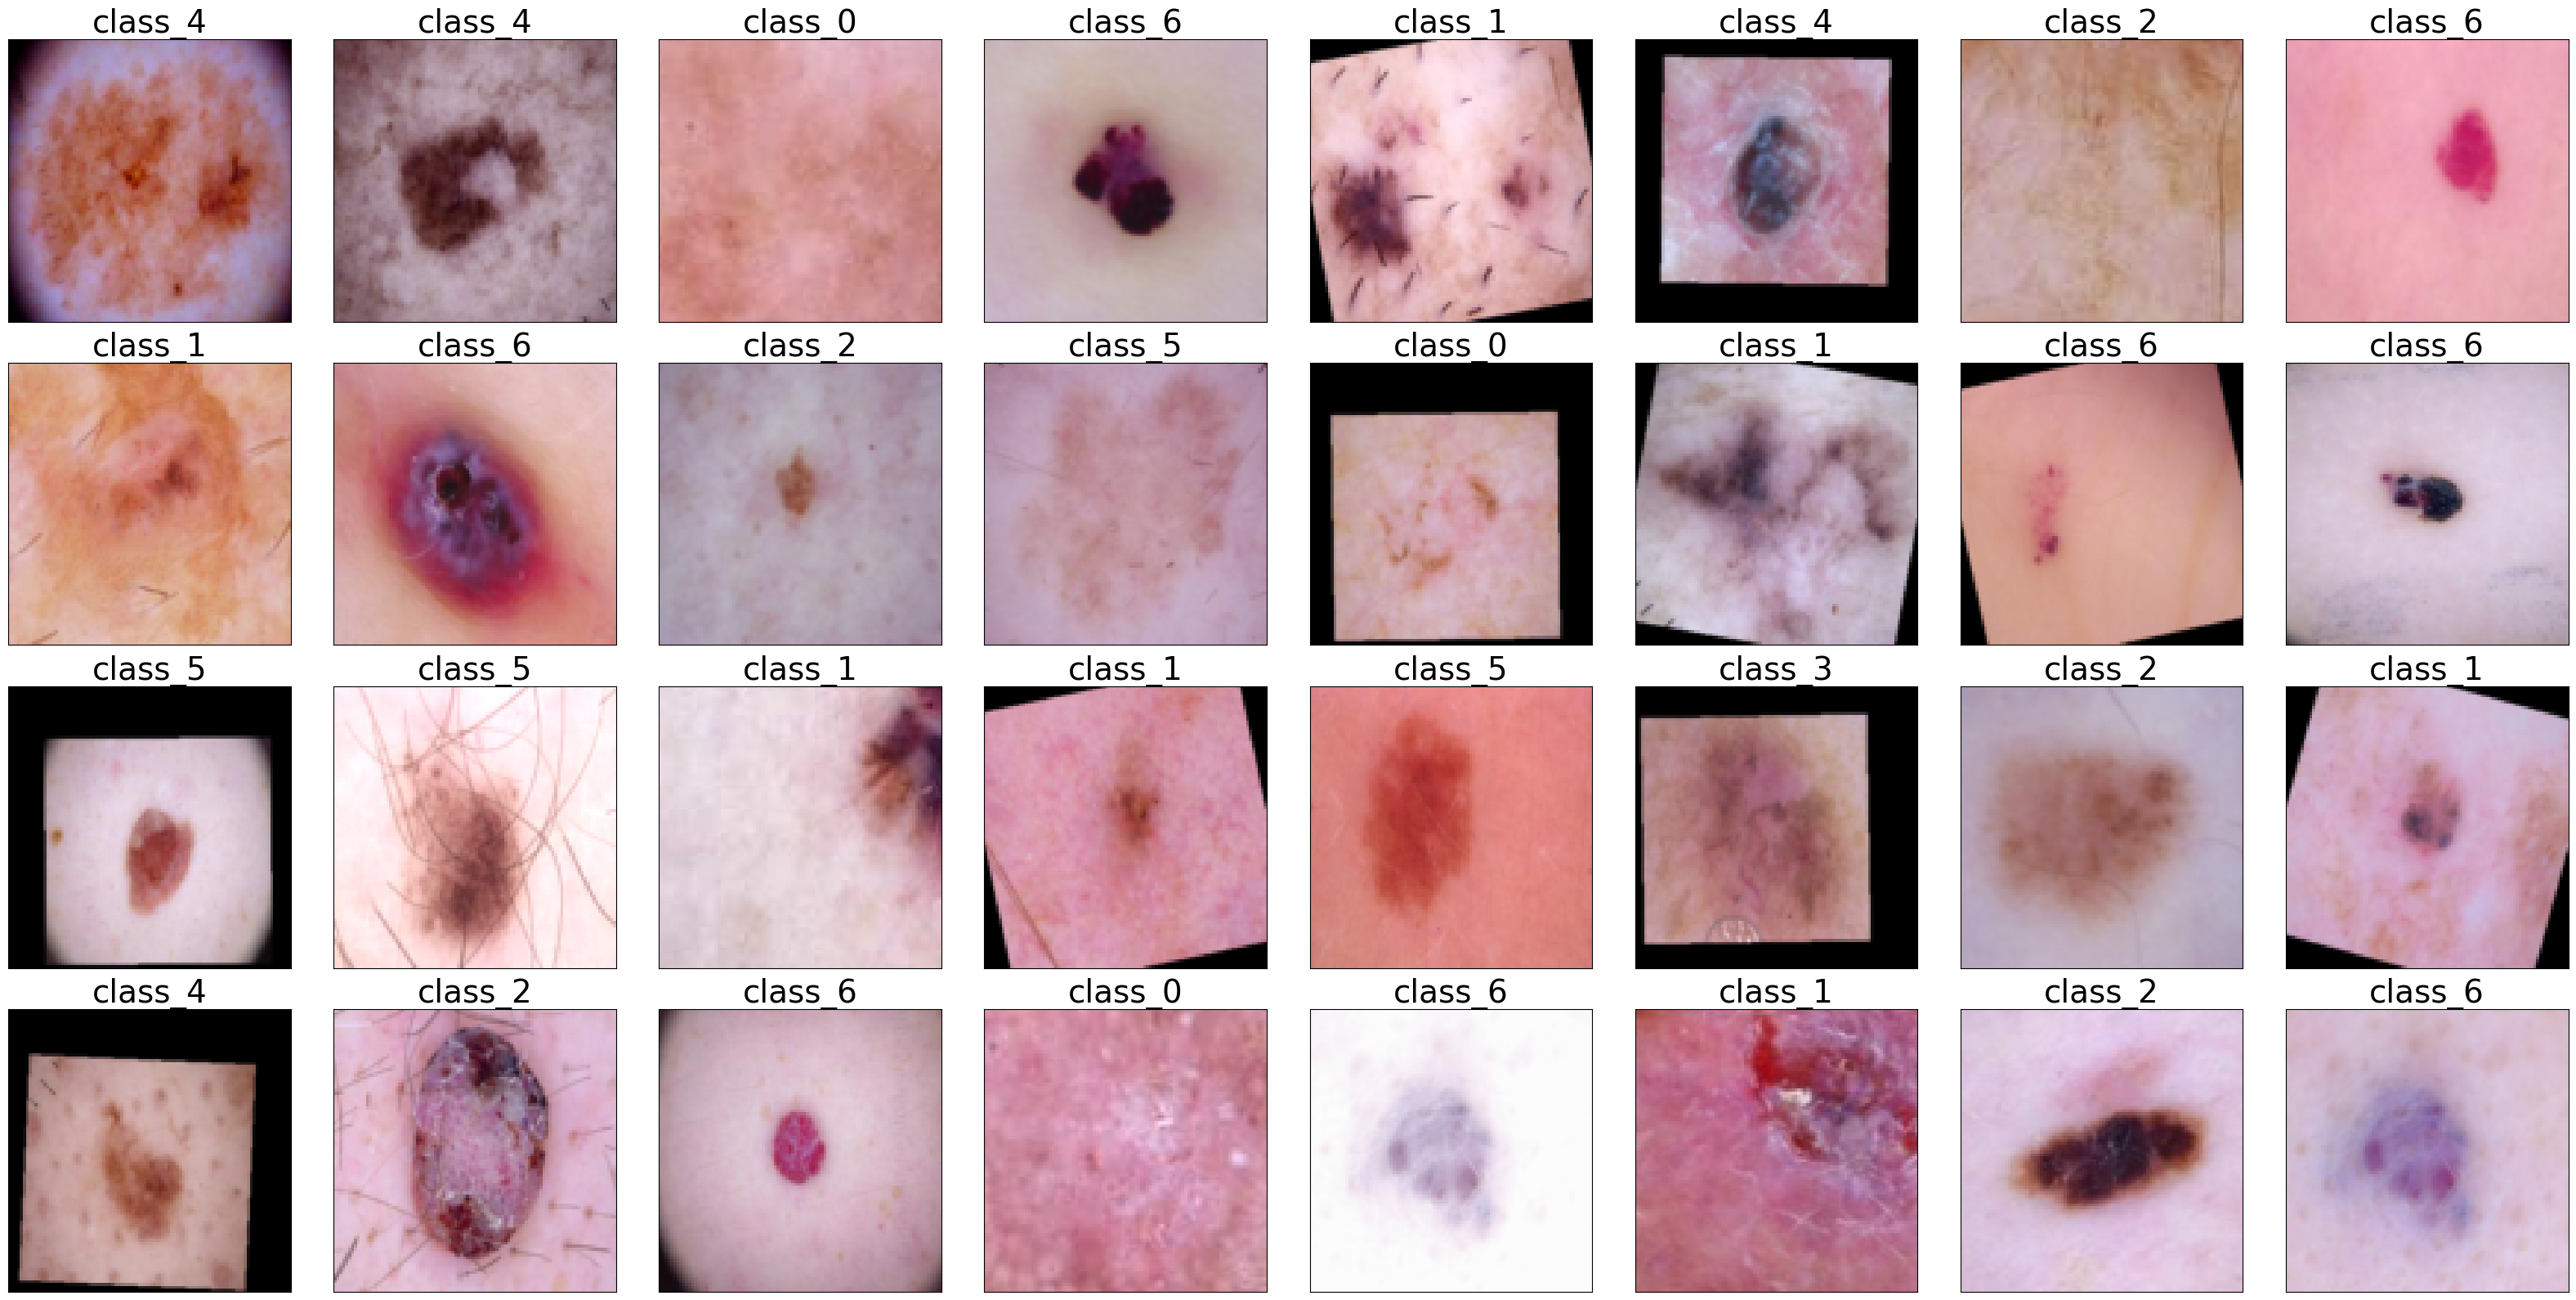

In [ ]:
%%time

import itertools
import numpy as np
import os

nrows,ncols = rows_cols(batch_size)

fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*4,nrows*4),
                       subplot_kw={'facecolor': "#ebf5ff"})
rb_index = np.random.randint(0, len(train_dataloader))

# Obtener el batch correspondiente al índice aleatorio
imgs, labels = next(itertools.islice(train_dataloader, rb_index, rb_index+1))
print(type(imgs),imgs.shape)

for i, ax in enumerate(ax.flatten()):
  ax.set_xticks([])
  ax.set_yticks([])
  ax.set_title(classes[labels[i]], fontsize=28)
  ax.imshow(inv_normalize(imgs[i]).permute(1,2,0)) # para las no normalizadas

fig.tight_layout()

### 3. **Define a [Convolutional Neural Network](https://pytorch.org/docs/stable/nn.html)**


Importo las librerías necesarias para definir la red CNN

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

Defino el modelo (clase myCNN).
6 capas convolucionares y 2 fully connected.

In [ ]:

import torch.nn as nn

class myCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Defino la parte convolucional de la red utilizando nn.Sequential
        self.network = nn.Sequential(
            # Layer 1: Conv2d -> BatchNorm -> ReLU
            # Input: 3 channels (RGB image), Output: 32 feature maps, kernel size 3x3, padding 1 for same size output
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            # Layer 2: Conv2d -> BatchNorm -> ReLU
            # Input: 32 feature maps, Output: 64 feature maps, stride 1, padding 1
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Layer 3: MaxPool2d
            # Reduce las dimensiones espaciales en 2 (la altura y el ancho se reducen a la mitad)
            nn.MaxPool2d(2, 2),

            # Layer 4: Conv2d -> BatchNorm -> ReLU
            # Input: 64 feature maps, Output: 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            # Layer 5: Conv2d -> BatchNorm -> ReLU
            # Segunda capa convolucional de 128 canales para una feature extraction más profunda
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            # Layer 6: MaxPool2d
            # Reduce aún más las dimensiones espaciales a la mitad
            nn.MaxPool2d(2, 2),

            # Layer 7: Conv2d -> BatchNorm -> ReLU
            # Input: 128 feature maps, Output: 256 feature maps
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            # Layer 8: Conv2d -> BatchNorm -> ReLU
            # Feature extraction más profunda con otra capa de 256 canales
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            # Layer 9: MaxPool2d
            # Reducción de muestreo espacial, reducción de dimensiones antes del pooling final
            nn.MaxPool2d(2, 2),

            # Layer 10: Global Average Pooling
            # Reduce cada feature map a un único valor, convirtiendo el tamaño espacial a 1x1
            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Defino las capas fully connected
        self.fc_layers = nn.Sequential(
            # Layer 11: Linear -> BatchNorm -> ReLU -> Dropout
            # Primera capa fully connected con 256 funciones de entrada y 128 de salida
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.6),  # Aumentamos en un 0.1 el Dropout para reducir overfitting

            # Layer 12: Linear -> BatchNorm -> ReLU -> Dropout
            # Segunda capa fully connected con 128 entradas y 64 salidas
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.6),

            # Layer 13: Linear
            # Última capa fully connected para generar 7 clases (para un problema de clasificación de 7 clases)
            nn.Linear(64, 7)
        )

    def forward(self, xb):
        # Pasa la entrada a través de las capas convolucionales
        xb = self.network(xb)

        # Aplana el tensor para la entrada a las capas fully connected
        xb = xb.view(xb.size(0), -1)

        # Pasa a través de las capas fully connected
        xb = self.fc_layers(xb)

        return xb

# Función de inicialización de Weight
def weights_init(m):
    """
    Custom weight initialization function.
    Applies Kaiming He initialization to Conv2d and Linear layers for better convergence.
    """
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        # Kaiming He initialization (buena para activaciones ReLU)
        nn.init.kaiming_normal_(m.weight, nonlinearity='relu')

        # Inicializa los sesgos a cero si existen
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)




### Setting the Computing Device



Coloco el modelo en la device Cuda (GPU), que es capaz de manejar tensores muy facilmente de manera paralela.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

model = myCNN().to(device)
model.apply(weights_init)
if torch.cuda.device_count() > 1:
  print("Let's use", torch.cuda.device_count(), "GPUs!")
  model = nn.DataParallel(model)

print(model)

Using cuda device
myCNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(128, 256, kernel_size=(3, 3), stride=

Muestro un resumen del modelo con entrada 96*96

In [ ]:
%pip install torchsummary -q

#Actualiza el resumen para reflejar la nueva resolución
from torchsummary import summary

summary(model, (3,96,96)) # input = [3,96,96]

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 96, 96]             896
       BatchNorm2d-2           [-1, 32, 96, 96]              64
              ReLU-3           [-1, 32, 96, 96]               0
            Conv2d-4           [-1, 64, 96, 96]          18,496
       BatchNorm2d-5           [-1, 64, 96, 96]             128
              ReLU-6           [-1, 64, 96, 96]               0
         MaxPool2d-7           [-1, 64, 48, 48]               0
            Conv2d-8          [-1, 128, 48, 48]          73,856
       BatchNorm2d-9          [-1, 128, 48, 48]             256
             ReLU-10          [-1, 128, 48, 48]               0
           Conv2d-11          [-1, 128, 48, 48]         147,584
      BatchNorm2d-12          [-1, 128, 48, 48]             256
             ReLU-13          [-1, 128, 48, 48]               0
        MaxPool2d-14          [-1, 128,

### Define a Loss function and optimizer


Defino la función de pérdida y el optimizador. Elijo Adam y un nuevo valor para el learning rate=0.0005

In [ ]:
criterion = nn.CrossEntropyLoss() #Apropiada para la segmentación multiclase

# Definimos nuestro optimizador Adam ---> Estándar para entrenamiento rápido
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005) #Bajando el lr=0.0005 mejoramos la estabilidad y reducimos oscilaciones.

epochs= 40

## 4. **Train the network**

Función de entrenamiento por epoch

In [ ]:
def train(dataloader, model, criterion, optimizer):
  running_loss, corrects, current = 0, 0, 0
  size = len(dataloader.dataset) # número de imágenes del dataset
  print(f"Training:")
  model.train()
  loop = tqdm(train_dataloader)
  for batch, (X, y) in enumerate(loop):
    X, y = X.to(device), y.to(device) # Mover los datos y las etiquetas al dispositivo (CPU o GPU)

    # forward pass
    preds = model(X) # Calcular predicciones
    loss = criterion(preds, y) # Calcular la pérdida entre predicciones y etiquetas

    # backpropagation
    optimizer.zero_grad()   # Pone a cero los gradient buffers
    loss.backward()         # calcula gradients to backwards
    optimizer.step()        # Realiza el "update weights" del

    # Calcula Output Metrics training_loss, training_accuracy

    # 1. loss.item() Contiene la pérdida de todo el mini-batch convertido a escalar
    running_loss += loss.item() # Acumula la pérdida de este batch

    # 2. imagen actual (última imagen del batch) para barra progresiva
    current += len(X) # Actualiza el número actual de imágenes procesadas

    # 3.De las predicciones, selecciono el índice (clase) de la que tiene el valor más alto
    # y lo comparo con la etiqueta (clase). El valor booleano se convierte en un valor de punto
    # flotante (true se convierte en 1, false se convierte en 0) y todos se suman.
    # Finalmente, 'item' los convierte en un valor escalar.
    # De esta manera, 'corrects' refleja el número de predicciones correctas (precisión).
    corrects += (preds.argmax(1) == y).type(torch.float).sum().item()

    # 4. running loss es la suma de nuestras pérdidas.
    # La pérdida de entrenamiento es un promedio móvil a través de los batches.
    training_loss = running_loss/(batch+1)

    # 5. Training accuracy = Número de predicciones correctas/número de imágenes procesadas
    training_accuracy = corrects/current

    # Actualice la barra de progreso con la época, el batch y las métricas actuales
    loop.set_description(f'[{epoch + 1}/{epochs} epochs, {current:>5d}/{len(train_dataloader.dataset):>5d} data]')
    loop.set_postfix(Training_Loss=training_loss, Accuracy=f'{100*corrects/current:>0.1f}%')

  return training_loss, training_accuracy

Función val para evaular en un DataLoader de validación

In [ ]:
def val(dataloader, model, criterion):
  size = len(dataloader.dataset)
  num_batches = len(dataloader)

  model.eval()

  val_loss, corrects = 0, 0
  with torch.no_grad():
    for X, y in dataloader:
      X, y = X.to(device), y.to(device)

  # predicción para un conjunto de datos no utilizado en el entrenamiento
  # calcular el error de predicción y el número de aciertos
  # mediante batches
      preds = model(X)
      val_loss += criterion(preds, y).item()
      corrects += (preds.argmax(1) == y).type(torch.float).sum().item()
  val_loss /= num_batches
  corrects /= size
  print(f"Val: \n Accuracy: {(100*corrects):>0.1f}%, val_Loss: {val_loss:>8f} \n")

  return val_loss, corrects

Creo un directorio de entrenamiento para almacenar checkpoints

In [ ]:
import os
import torchvision.models as models

def create_train_dir():
    """
    Creates a sequentially numbered 'train' directory in the current directory.
    """

    # Obtengo la ruta del directorio actual
    current_dir = os.getcwd()
    print(current_dir)

    # Enumero los directorios en el directorio actual que comienzan con 'train' y terminan con un número
    train_dirs = [d for d in os.listdir(current_dir) if d.startswith('train') and d[5:].isdigit()]

    # CCalcular el número para el próximo directorio 'train' basándose en los directorios existentes
    next_train_num = len(train_dirs) + 1
    train_dir = os.path.join(current_dir, f'train{next_train_num}')  # Defino la nueva ruta del directorio

    # Creo el nuevo directorio 'tren'
    os.makedirs(train_dir, exist_ok=True)
    print(f"Training directory created: {train_dir}")
    return train_dir

Defino las funciones de checkpoint y de resume.

In [ ]:
import torch
import csv

# Guarda el estado de optimizer y modelo, y escribe un archivo CSV
# con historial para escribir métricas de entrenamiento/validación.

def checkpoint(model, filename):
    """
    Saves the current state of the model and optimizer to a checkpoint file.
    Additionally, writes the training and validation history to a CSV file.

    Parameters:
    - model: The model to save.
    - filename: The base name for saving the checkpoint and CSV files.
    """
    torch.save({
        'optimizer': optimizer.state_dict(),
        'model': model.state_dict(),
    }, filename)

    with open(f'{filename}.csv', 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)

        writer.writerow(['Epoch', 'Train Loss', 'Train Accuracy', 'Val Loss', 'Val Accuracy'])

        for epoch, (train_loss, train_accuracy, val_loss, val_accuracy) in enumerate(zip(loss_train_history, accuracy_train_history, loss_val_history, accuracy_val_history)):
            writer.writerow([epoch + 1, train_loss, train_accuracy, val_loss, val_accuracy])  # Write row for each epoch

def resume(model, filename):
    """
    Loads a saved checkpoint to restore the model and optimizer state.

    Parameters:
    - model: The model to which the saved parameters should be loaded.
    - filename: The file from which to load the checkpoint.
    """
    # Carga los parámetros del modelo guardados
    model.load_state_dict(torch.load(filename, weights_only=True )['model'])

    # Carga el estado del optimizador guardado
    optimizer.load_state_dict(torch.load(filename, weights_only=True)['optimizer'])



Defino el bucle de entrenamiento con Early Stopping

In [ ]:
%%time

from tqdm import tqdm
import csv

early_stop_thresh = 7
best_accuracy = -1
best_epoch = -1


loss_train_history = []
accuracy_train_history = []
loss_val_history = []
accuracy_val_history = []

#Crear directorio para almacenar métricas de entrenamiento
os.chdir(HOME)
train_dir = create_train_dir()


for epoch in range(epochs):
  loss_train,acc_train = train(train_dataloader, model, criterion, optimizer)
  loss_train_history.append(loss_train)
  accuracy_train_history.append(acc_train)
  loss_val,acc_val= val(val_dataloader, model, criterion)
  loss_val_history.append(loss_val)
  accuracy_val_history.append(acc_val)
  if acc_val > best_accuracy:
    best_accuracy = acc_val
    best_epoch = epoch+1
    checkpoint(model, os.path.join(train_dir,"best_model.pth"))
    print(f'best model in epoch={epoch+1} with Accuracy={(100*acc_val):>0.1f}%')
  elif epoch - best_epoch >= early_stop_thresh:
    print(f"Early stopped training at epoch {epoch+1} due to {early_stop_thresh} epochs whitout enhacement")
    break
print("Done!. Finished Training")

/content
Training directory created: /content/train2
Training:


[1/40 epochs, 58800/58800 data]: 100%|██████████| 1838/1838 [03:07<00:00,  9.82it/s, Accuracy=34.6%, Training_Loss=1.75]


Val: 
 Accuracy: 49.1%, val_Loss: 1.330829 

best model in epoch=1 with Accuracy=49.1%
Training:


[2/40 epochs, 58800/58800 data]: 100%|██████████| 1838/1838 [02:42<00:00, 11.34it/s, Accuracy=46.7%, Training_Loss=1.39]


Val: 
 Accuracy: 58.9%, val_Loss: 1.138850 

best model in epoch=2 with Accuracy=58.9%
Training:


[3/40 epochs, 58800/58800 data]: 100%|██████████| 1838/1838 [02:38<00:00, 11.58it/s, Accuracy=53.0%, Training_Loss=1.26]


... (59 outputs left out)

[33/40 epochs, 58800/58800 data]: 100%|██████████| 1838/1838 [02:34<00:00, 11.92it/s, Accuracy=88.8%, Training_Loss=0.346]


Val: 
 Accuracy: 72.7%, val_Loss: 1.039221 

Training:


[34/40 epochs, 58800/58800 data]: 100%|██████████| 1838/1838 [02:35<00:00, 11.81it/s, Accuracy=89.2%, Training_Loss=0.338]


Val: 
 Accuracy: 73.0%, val_Loss: 0.978844 

Early stopped training at epoch 34 due to 7 epochs whitout enhacement
Done!. Finished Training
CPU times: user 23min 35s, sys: 1min 49s, total: 25min 24s
Wall time: 1h 36min 21s


visualización de curvas métricas de entrenamiento y validación (dibuja loss y accuracy de train/val).

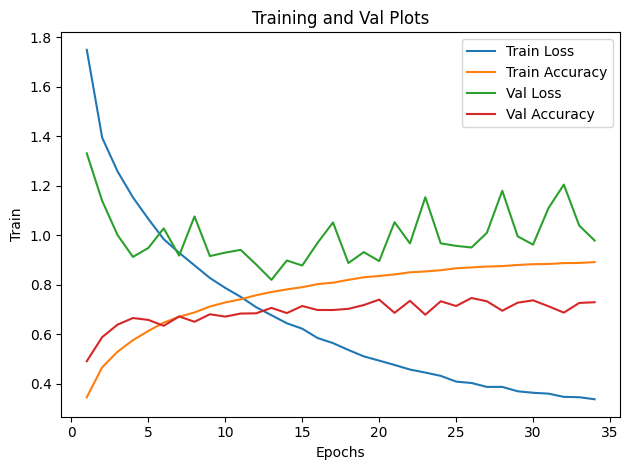

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.set_title('Training and Val Plots')
ax.plot(range(1,len(loss_train_history)+1), loss_train_history, label="Train Loss")
ax.plot(range(1,len(loss_train_history)+1), accuracy_train_history, label="Train Accuracy")
ax.plot(range(1,len(loss_train_history)+1), loss_val_history, label="Val Loss")
ax.plot(range(1,len(loss_train_history)+1), accuracy_val_history, label="Val Accuracy")
ax.set_xlabel("Epochs")
ax.set_ylabel("Train")
ax.legend()

fig.tight_layout()

## 5. **Validating our model**

Funciones de validación y predicción, (obtengo predicciones sobre un dataloader).
Cargo el mejor modelo guardado y calculo la matriz de confusión y métricas.

In [ ]:
import torch
import os
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix
import numpy as np

# Defino una función para obtener las predicciones del modelo
def obtener_predicciones(modelo, dataloader):
    preds = []
    etiquetas = []
    for batch in dataloader:
        inputs, etiquetas_batch = batch
        inputs = inputs.to(device)
        outputs = modelo(inputs)
        _, predicciones = torch.max(outputs, 1)
        preds.extend(predicciones.tolist())
        etiquetas.extend(etiquetas_batch.tolist())
    return preds, etiquetas

#Cargo el checkpoint y evaluo en el set de validación

# Define el dispositivo (Cuda) en el que se realizarán las operaciones
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Carga el modelo guardado
model_file = os.path.join(train_dir, "best_model.pth")
checkpoint = torch.load(model_file, map_location=device)
model_state_dict = checkpoint['model']

# Defino y cargo el modelo
model = myCNN()
model.load_state_dict(model_state_dict)
model.to(device)
model.eval()

# Obtengo predicciones del modelo y etiquetas verdaderas del conjunto de validación.
predicciones_val, etiquetas_val = obtener_predicciones(model, val_dataloader)

# Calculo la matriz de confusión
cm = confusion_matrix(etiquetas_val, predicciones_val)

print("Matriz de Confusión:")
print(cm)

# Calculo el accuracy por clase
precision_por_clase = cm.diagonal() / cm.sum(axis=0)
print("Precisión por clase:", precision_por_clase)

recall_por_clase = cm.diagonal() / cm.sum(axis=1)
print("Recall por clase:", recall_por_clase)

# Calculo F1 score por caso
f1_por_clase = 2 * (precision_por_clase * recall_por_clase) / (precision_por_clase + recall_por_clase)
print("F1-score por clase:", f1_por_clase)


Matriz de Confusión:
[[ 92  15  22   5  11   5   0]
 [  6 116  13   0   3   5   7]
 [ 11   3 102   8  15  10   1]
 [ 11  16   1 121   1   0   0]
 [  4   1  29   1 104  10   1]
 [  0   4   6   2  17 118   3]
 [  0   3   0   1   0  15 131]]
Precisión por clase: [0.74193548 0.73417722 0.58959538 0.87681159 0.68874172 0.72392638
 0.91608392]
Recall por clase: [0.61333333 0.77333333 0.68       0.80666667 0.69333333 0.78666667
 0.87333333]
F1-score por clase: [0.67153285 0.75324675 0.63157895 0.84027778 0.6910299  0.75399361
 0.89419795]


Visualizo la Matriz de Confusión en un heatmap con seaborn.

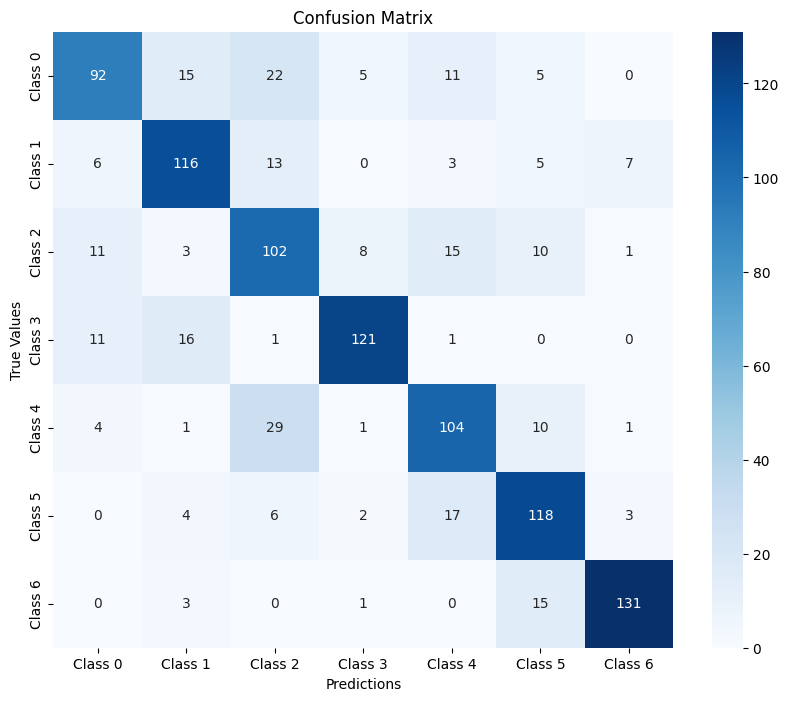

In [ ]:
%pip install seaborn -q

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Suponiendo que 'etiquetas_val' son las etiquetas verdaderas y 'predicciones_val' son las predicciones del modelo

cm = confusion_matrix(etiquetas_val, predicciones_val)

# Definir las etiquetas para la matriz de confusión
labels = [f'Class {i}' for i in range(len(cm))]

# Crear un Pandas DataFrame para la matriz de confusión
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_df, annot=True, cmap='Blues', fmt='g')
plt.title('Confusion Matrix')
plt.xlabel('Predictions')
plt.ylabel('True Values')
plt.show()


Calculo y dibujo las curvas ROC de todas las clases

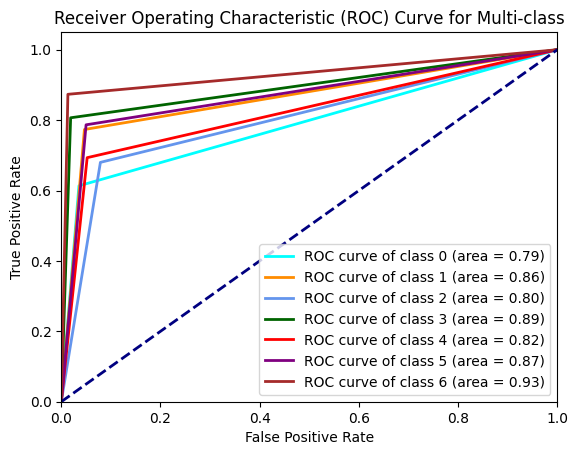

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Supongamos que 'predicciones_val' y 'etiquetas_val' son las predicciones y etiquetas verdaderas del conjunto de validación
# Obtenidas previamente usando la función obtener_predicciones()

# Número de clases
n_classes = len(set(etiquetas_val))

# Binarizar las etiquetas
etiquetas_val_binarized = label_binarize(etiquetas_val, classes=[i for i in range(n_classes)])
predicciones_val_binarized = label_binarize(predicciones_val, classes=[i for i in range(n_classes)])

# Calcular la curva ROC y el AUC para cada clase
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(etiquetas_val_binarized[:, i], predicciones_val_binarized[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Graficar todas las curvas ROC
plt.figure()
colors = ['aqua', 'darkorange', 'cornflowerblue', 'darkgreen', 'red', 'purple', 'brown']
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2, label=f'ROC curve of class {i} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Multi-class')
plt.legend(loc="lower right")
plt.show()


## 6. **Predictions** (Inference)

Ajustes para inferencia en test set y función para predecir en un dataloader durante inferencia (retorna preds y labels).

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


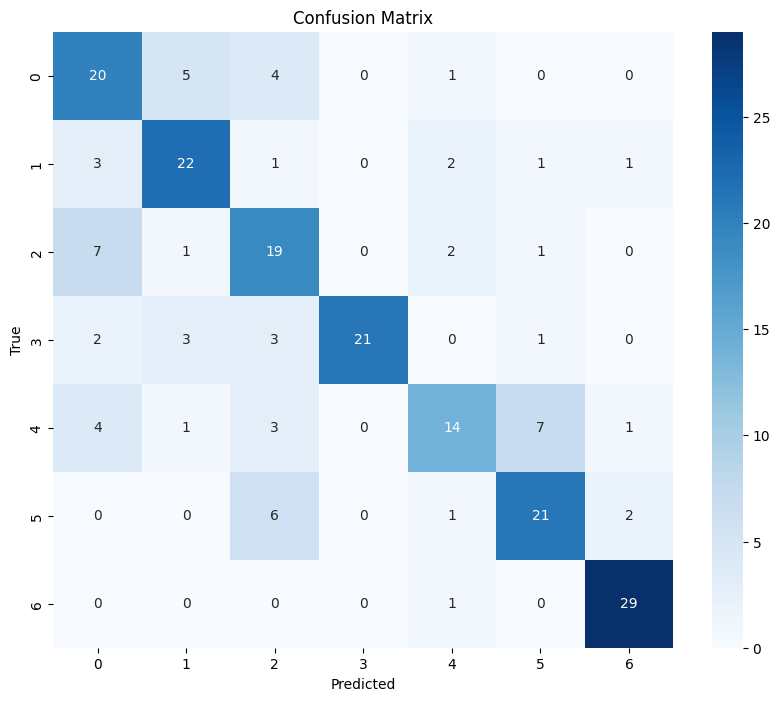

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.67      0.61        30
           1       0.69      0.73      0.71        30
           2       0.53      0.63      0.58        30
           3       1.00      0.70      0.82        30
           4       0.67      0.47      0.55        30
           5       0.68      0.70      0.69        30
           6       0.88      0.97      0.92        30

    accuracy                           0.70       210
   macro avg       0.71      0.70      0.70       210
weighted avg       0.71      0.70      0.70       210

Confusion matrix shape: (7, 7), not a binary classification problem.


In [ ]:
import torch
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Definir el directorio de prueba
test_dir = f"{HOME}/datasets/test/"

# Definir parámetros de normalización
mean = torch.tensor([0.7536, 0.5706, 0.6018])
std = torch.tensor([0.0849, 0.1106, 0.1187])
batch_size = 32

# Crear el dataset de prueba y el dataloader
test_set = datasets.ImageFolder(test_dir, transform=transforms.Compose([
    transforms.Resize((96,96)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
]))

test_dataloader = DataLoader(
    test_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=4
)

# Definir una función para obtener predicciones del modelo
def obtener_predicciones(modelo, dataloader):
    preds = []
    etiquetas = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, etiquetas_batch = batch
            inputs = inputs.to(device)
            outputs = modelo(inputs)
            _, predicciones = torch.max(outputs, 1)
            preds.extend(predicciones.tolist())
            etiquetas.extend(etiquetas_batch.tolist())
    return preds, etiquetas

# Defino el dispositivo (Cuda)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = myCNN()

# Cargar el punto de control del modelo
checkpoint = torch.load(f"{HOME}/train1/best_model.pth", weights_only=True, map_location=device)
model.load_state_dict(checkpoint['model'])
model.to(device)
model.eval()

# Obtengo predicciones del modelo y etiquetas verdaderas del conjunto de prueba
predicciones_test, etiquetas_test = obtener_predicciones(model, test_dataloader)

# Calculo la matriz de confusión
cm = confusion_matrix(etiquetas_test, predicciones_test)

# Dibujo la matriz de confusión
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Imprimir informe de clasificación
print("Classification Report:")
print(classification_report(etiquetas_test, predicciones_test))

# Comprobar si clasificación binaria
if cm.shape == (2, 2):
    tn, fp, fn, tp = cm.ravel()
    print("True Negatives (TN):", tn)
    print("False Positives (FP):", fp)
    print("False Negatives (FN):", fn)
    print("True Positives (TP):", tp)
else:
    print(f"Confusion matrix shape: {cm.shape}, not a binary classification problem.")

Muestro las curvas ROC multiclas en test set y observo el cambio

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


7


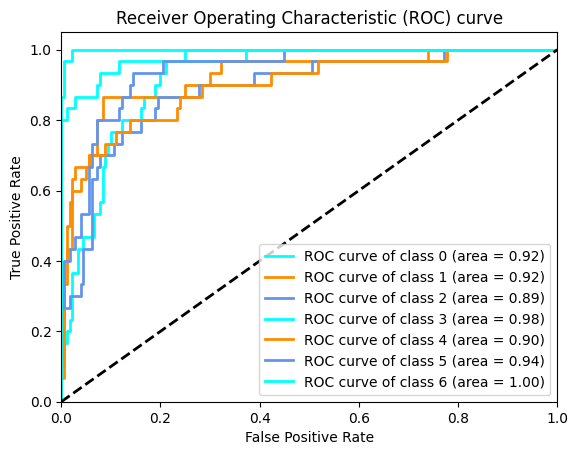

In [ ]:
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve, auc
from itertools import cycle

# Defino una función para obtener predicciones del modelo
def obtener_predicciones(modelo, dataloader):
    preds = []
    etiquetas = []
    probas = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, etiquetas_batch = batch
            inputs = inputs.to(device)
            outputs = modelo(inputs)
            _, predicciones = torch.max(outputs, 1)
            preds.extend(predicciones.tolist())
            etiquetas.extend(etiquetas_batch.tolist())
            probas.extend(outputs.tolist())
    return preds, etiquetas, probas

# Obtengo predicciones del modelo y etiquetas verdaderas del conjunto de prueba
predicciones_test, etiquetas_test, probas_test = obtener_predicciones(model, test_dataloader)

# Binarizar la salida
n_classes = len(test_set.classes)
print(n_classes)
etiquetas_test_binarized = label_binarize(etiquetas_test, classes=range(n_classes))

# Calcular la curva ROC y el área ROC para cada clase
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(etiquetas_test_binarized[:, i], np.array(probas_test)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Calcular la curva ROC micropromedio y el área ROC
fpr["micro"], tpr["micro"], _ = roc_curve(etiquetas_test_binarized.ravel(), np.array(probas_test).ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Dibujo las curvas ROC
plt.figure()
colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) curve')
plt.legend(loc="lower right")
plt.show()

#**Procedimiento y Conclusiones**

1) En primer lugar, al principio trabajamos con imágenes de 64×64 porque era lo más seguro para evitar problemas de memoria. Pero después de revisar bien la GPU que estábamos usando (Tesla T4 con 15 GB), vimos que podiamos subir la resolución.

  Al pasar las imágenes a 96×96, el modelo recibe más información visual y le ayuda a captar mas detalles. Es verdad que entrenar con imágenes más grandes tarda un poco más, pero compensa porque el modelo aprende mejor y diferencia mejor unas clases de otras. En nuestro caso no hemos tenido problemas de memoria.

2) Luego, hemos comenzado aumentando el data augmentation añadiendo transformaciones como rotaciones más amplias, mayor color jitter, desenfoque (ruido) y una deformación geométrica suave del ±3°.

Al incrementar la variedad de imágenes, el modelo ha aprendido representaciones más generales y robustas. Lo que fuerza al modelo a dejar de memorizar y le obliga a centrarse en patrones relevantes.

3) Hemos probado inicialmente un batch size= 64 y hemos observado que al haber menos iteraciones por epoch hay menos pasos en el bucle, menos tiempos de overhead y, por tanto, más velocidad en el entrenamiento. Sin embargo, cuanto más aumentemos nuestro bach size más riesgo hay de quedarnos sin memoria (no ha sido nuestro caso).

La razón por la que hemos decidido reducir el bach size a 32 ha sido por un claro overfitting, ya que a partir de la epoch 10 el modelo ha empezado a sobreentrenarse, es decir, a memorizar.

Dicho esto, aunque nos tome más tiempo de entrenamiento, un batch size de 32 es muy buena opción para nuestro entrenamiento ya que hemos visto una mejora de la validación (menos overfitting).

4) También, al aumentar num_workers de 2 a 4, duplicamos la cantidad de procesos que preparan los lotes en paralelo. Esto ha permitido que la GPU trabaje de manera más continua, evitando tiempos muertos por espera de datos.

Gracias a este ajuste, el entrenamiento se vuelve más eficiente.

5) Por otro lado, comenzamos entrenando con un learning rate estándar de 0.001 en el optimizador Adam, pero observamos oscilaciones fuertes en la curva de validación. Ya que el modelo actualizaba los pesos demasiado bruscamente, lo que dificultaba que encontrase mínimos estables.

Al reducir el learning rate a 0.0005, hemos conseguido pasos más pequeños y precisos durante el entrenamiento. Lo que suaviza el aprendizaje, evita saltos bruscos y mejora la estabilidad. De esta manera hemos obtenido una validación más consistente y una reducción del overfitting.

6) En un principio utilizamos un dropout del 0.5, lo cual ya era una medida razonable contra el sobreentrenamiento. Sin embargo, el análisis de las curvas de entrenamiento mostró que el modelo seguía memorizando demasiado rápido.

Por eso aumentamos el dropout a 0.6, eliminando aleatoriamente un 60% de las neuronas en cada forward pass. Esto fuerza aún más al modelo a construir representaciones más generalizadas.

Aunque un dropout más alto puede ralentizar un poco el aprendizaje, hemos comprobado que ayuda a reducir el overfitting sin degradar la precisión final del modelo.






En conclusión, después de aplicar todas las mejoras, el modelo ha rendido mejor que en la versión original.

La pérdida de entrenamiento baja más rápido, las curvas son más estables y la precisión global sube ligeramente. También se nota una mejora en varias clases (1, 3 y 6), y en las clases más problemáticas al menos se ve un pequeño avance (2 y 4).

Gracias a los cambios: aumentar resolución, ajustar batch size, parámetros del entrenamiento... el modelo ahora es un poco más robusto y muestra menos overfitting que antes, aunque todavía hay margen de mejora por la dificultad del propio dataset.